# IMDB sentiment: fine-tuning pretrained transformers (DistilBERT, BERT, RoBERTa)

**Research question.** In `imdb_baselines_bigru_transformer.ipynb`, no model trained from scratch beat a bag-of-words
baseline (88.05% test accuracy). Does starting from a pretrained language model change that? And how much of the
pretrained model needs to be retrained: only a new output layer, a few top layers, or everything?

**Why it might help.** The earlier models started from random weights and had to learn English from 20k reviews. A
pretrained model has already learned general English from billions of words (masked language modelling), so
fine-tuning only has to adapt it to sentiment.

Suggested by Prof. Matthew McNeill.

| Question | Where |
|---|---|
| Same data and split as the earlier notebooks, so results compare directly | section 1 |
| How many reviews exceed the models' 512-token limit, and what to keep | section 2 |
| Does the pipeline work? (chance-level start, overfit one batch) | section 4 |
| Mixed precision (bf16) vs. fp32 on the NVIDIA GPU | section 5 |
| How many top layers to unfreeze: head only, top 2, top 4, all | sections 7–9 |
| Is the result reproducible? | section 10 |
| BERT-base and RoBERTa-base with the best setting | section 11 |
| Comparison with the 88.05% bag-of-words baseline and the earlier models | sections 12–13 |

Plan: get everything working with **DistilBERT** (6 layers, 66M parameters, fast), then run the full-size **BERT-base** and
**RoBERTa-base** (12 layers, 110M and 125M) for the main result.

## 0. Setup

In [1]:
import random
import time
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from transformers import AutoTokenizer

SEED = 0
MAX_TOKENS = 512          # the models' limit, including the 2 special tokens
HEAD_TOKENS = 128         # for long reviews: keep the first 128 and the last 382 tokens
TAIL_TOKENS = MAX_TOKENS - 2 - HEAD_TOKENS

MODEL_NAMES = {"distilbert": "distilbert-base-uncased", "bert": "bert-base-uncased", "roberta": "roberta-base"}

device = torch.device("cuda")
print(torch.__version__, "|", torch.cuda.get_device_name(0), "| bf16:", torch.cuda.is_bf16_supported())

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

2.11.0+cu128 | NVIDIA GeForce RTX 4050 Laptop GPU | bf16: True


## 1. Data

Same files and same split as before: 25k labelled training reviews, shuffled with seed 0 into 20k train / 5k validation, plus the 25k test reviews.
The split code is copied unchanged from the previous notebook (same seed, same shuffle), so it produces the same split.

In [2]:
DATA_DIR = Path("data")
IMDB_URL = "https://huggingface.co/datasets/stanfordnlp/imdb/resolve/main/plain_text/{split}-00000-of-00001.parquet"

def load_split(split):
    path = DATA_DIR / f"imdb_{split}.parquet"
    if not path.exists():
        DATA_DIR.mkdir(exist_ok=True)
        urllib.request.urlretrieve(IMDB_URL.format(split=split), path)
    table = pd.read_parquet(path)
    return table["text"].tolist(), table["label"].tolist()

all_train_texts, all_train_labels = load_split("train")
test_texts, test_labels = load_split("test")

set_seed(SEED)
shuffled = list(range(len(all_train_texts)))
random.shuffle(shuffled)
train_indices, val_indices = shuffled[:20_000], shuffled[20_000:]
texts = {"train": [all_train_texts[i] for i in train_indices],
         "val": [all_train_texts[i] for i in val_indices],
         "test": test_texts}
labels = {"train": [all_train_labels[i] for i in train_indices],
          "val": [all_train_labels[i] for i in val_indices],
          "test": test_labels}

for split in texts:
    print(f"{split:>5}: {len(texts[split]):>6} reviews, {np.mean(labels[split]):.1%} positive")
print("first 5 validation indices:", val_indices[:5])

train:  20000 reviews, 50.1% positive
  val:   5000 reviews, 49.6% positive
 test:  25000 reviews, 50.0% positive
first 5 validation indices: [13123, 10099, 17643, 19039, 24203]


**Cleaning.** IMDB reviews contain HTML line breaks (`<br />`). The pretrained tokenizers would split them into pieces like
`<`, `br`, `/`, `>`, which carry no meaning and use up the 512-token budget. They're replaced with a space before tokenizing.
Nothing else is changed: these tokenizers handle case, punctuation and rare words themselves.

In [3]:
br_count = sum(text.count("<br />") for split in texts for text in texts[split])
texts = {split: [text.replace("<br />", " ") for text in split_texts] for split, split_texts in texts.items()}
print(f"replaced {br_count:,} '<br />' tags")
assert not any("<br" in text for split in texts for text in texts[split])

replaced 201,948 '<br />' tags


## 2. Tokenization and the 512-token limit

Each pretrained model must use **its own tokenizer**: it learned one embedding per token id during pretraining, so ids from
any other vocabulary would be meaningless to it. The tokenizers split rare words into subword pieces, so there's no `<unk>` problem.

- DistilBERT and BERT: WordPiece, 30,522 tokens, lower-cases the text. DistilBERT was distilled from BERT and uses exactly
  the same tokenizer, so their encoded reviews are identical.
- RoBERTa: byte-level BPE, 50,265 tokens, keeps case.

The models only have position embeddings for 512 positions, so longer reviews can't be fed in whole. First, how many reviews are affected?

In [4]:
tokenizers = {name: AutoTokenizer.from_pretrained(path) for name, path in MODEL_NAMES.items()}

example = "This movie was unwatchable, a total snoozefest!"
for name, tok in tokenizers.items():
    print(f"{name:>10}: {tok.tokenize(example)}")

# token ids without special tokens and without truncation, so the true lengths can be measured
token_ids = {name: {split: tok(split_texts, add_special_tokens=False)["input_ids"]
                    for split, split_texts in texts.items()}
             for name, tok in tokenizers.items()}

print()
for name in tokenizers:
    for split in texts:
        lengths = np.array([len(ids) for ids in token_ids[name][split]])
        long = lengths > MAX_TOKENS - 2
        print(f"{name:>10} {split:>5}: median {np.median(lengths):>4.0f} | 95th pct {np.percentile(lengths, 95):>5.0f} | "
              f"max {lengths.max():>5} | over the limit: {long.mean():6.1%} of reviews, "
              f"{np.maximum(lengths - (MAX_TOKENS - 2), 0).sum() / lengths.sum():5.1%} of tokens")
    assert min(len(ids) for split in texts for ids in token_ids[name][split]) > 0, "an empty review exists"

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

distilbert: ['this', 'movie', 'was', 'un', '##watch', '##able', ',', 'a', 'total', 's', '##no', '##oz', '##efe', '##st', '!']
      bert: ['this', 'movie', 'was', 'un', '##watch', '##able', ',', 'a', 'total', 's', '##no', '##oz', '##efe', '##st', '!']
   roberta: ['This', 'Ġmovie', 'Ġwas', 'Ġunw', 'atch', 'able', ',', 'Ġa', 'Ġtotal', 'Ġsn', 'oo', 'z', 'ef', 'est', '!']


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (748 > 512). Running this sequence through the model will result in indexing errors


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (748 > 512). Running this sequence through the model will result in indexing errors


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (732 > 512). Running this sequence through the model will result in indexing errors



distilbert train: median  221 | 95th pct   757 | max  3045 | over the limit:  13.4% of reviews, 11.0% of tokens
distilbert   val: median  213 | 95th pct   768 | max  1972 | over the limit:  12.9% of reviews, 11.0% of tokens
distilbert  test: median  217 | 95th pct   741 | max  2873 | over the limit:  12.3% of reviews, 10.4% of tokens
      bert train: median  221 | 95th pct   757 | max  3045 | over the limit:  13.4% of reviews, 11.0% of tokens
      bert   val: median  213 | 95th pct   768 | max  1972 | over the limit:  12.9% of reviews, 11.0% of tokens
      bert  test: median  217 | 95th pct   741 | max  2873 | over the limit:  12.3% of reviews, 10.4% of tokens
   roberta train: median  217 | 95th pct   747 | max  3047 | over the limit:  13.0% of reviews, 10.8% of tokens
   roberta   val: median  210 | 95th pct   762 | max  1972 | over the limit:  12.4% of reviews, 10.7% of tokens
   roberta  test: median  213 | 95th pct   730 | max  2791 | over the limit:  12.0% of reviews, 10.1% o

**What to keep from a long review.** Keeping only the first 510 tokens is the usual default, but it drops the end of the
review, where people often state their verdict ("Overall, 3/10."). Sun et al. (2019), *How to Fine-Tune BERT for Text
Classification*, compared options on IMDB and found that the **first 128 + last 382 tokens** did best. That's what this
notebook uses. Reviews within the limit are kept whole.

In [5]:
def head_and_tail(ids):
    if len(ids) <= MAX_TOKENS - 2:
        return ids
    return ids[:HEAD_TOKENS] + ids[-TAIL_TOKENS:]

def encode_split(name, split):
    # single-sequence format for both models: [CLS] ... [SEP] (DistilBERT) and <s> ... </s> (RoBERTa)
    tok = tokenizers[name]
    return [[tok.cls_token_id] + head_and_tail(ids) + [tok.sep_token_id] for ids in token_ids[name][split]]

encoded = {name: {split: encode_split(name, split) for split in texts} for name in tokenizers}

# for a review within the limit, this must match what the tokenizer itself produces
for name, tok in tokenizers.items():
    short = next(i for i, ids in enumerate(token_ids[name]["train"]) if len(ids) < 100)
    assert encoded[name]["train"][short] == tok(texts["train"][short])["input_ids"]
print("encoding matches each tokenizer's own output for a short review")

for name, tok in tokenizers.items():
    ids = encoded[name]["train"][0]
    print(f"{name:>10}: longest encoded review {max(len(i) for s in texts for i in encoded[name][s])} tokens | "
          f"starts {tok.convert_ids_to_tokens(ids[:4])} ... ends {tok.convert_ids_to_tokens(ids[-3:])}")

encoding matches each tokenizer's own output for a short review
distilbert: longest encoded review 512 tokens | starts ['[CLS]', 'according', 'to', 'the'] ... ends ['market', '.', '[SEP]']
      bert: longest encoded review 512 tokens | starts ['[CLS]', 'according', 'to', 'the'] ... ends ['market', '.', '[SEP]']
   roberta: longest encoded review 512 tokens | starts ['<s>', 'According', 'Ġto', 'Ġthe'] ... ends ['Ġmarket', '.', '</s>']


## 3. Dataset and DataLoader

Reuses `ReviewDataset` and the length-bucketing `BucketBatchSampler` from [`imdb_data.py`](imdb_data.py). The collate
function is new because these models need two extra things:

- **Their own padding id**: 0 for DistilBERT, 1 for RoBERTa (the earlier notebooks used 0).
- **An attention mask**: 1 for real tokens and 0 for padding, so attention ignores the padding.

`BATCH_SIZE` is what fits in the GPU's 6 GB. Gradients are accumulated over `ACCUMULATE` batches before each optimizer
step, so each update sees `BATCH_SIZE × ACCUMULATE = 32` reviews.

In [6]:
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader

from imdb_data import BucketBatchSampler, ReviewDataset

BATCH_SIZE = 16
ACCUMULATE = 2            # 16 x 2 = 32 reviews per optimizer step

class Collate:
    # a class rather than a nested function, so DataLoader workers could pickle it on Windows
    def __init__(self, pad_id):
        self.pad_id = pad_id

    def __call__(self, batch):
        token_ids, batch_labels = zip(*batch)
        lengths = torch.tensor([len(ids) for ids in token_ids])
        input_ids = pad_sequence(token_ids, batch_first=True, padding_value=self.pad_id)
        attention_mask = (torch.arange(input_ids.shape[1]) < lengths[:, None]).long()
        return input_ids, attention_mask, torch.tensor(batch_labels)

def make_loader(name, split, batch_size=BATCH_SIZE):
    dataset = ReviewDataset(encoded[name][split], labels[split])
    is_train = split == "train"
    sampler = BucketBatchSampler([len(ids) for ids in encoded[name][split]], batch_size,
                                 shuffle=is_train, drop_last=is_train, seed=SEED)
    return DataLoader(dataset, batch_sampler=sampler, collate_fn=Collate(tokenizers[name].pad_token_id))

input_ids, attention_mask, batch_labels = next(iter(make_loader("distilbert", "train")))
print("input_ids", tuple(input_ids.shape), "| mask", tuple(attention_mask.shape), "| labels", batch_labels.tolist())
print("padding tokens in this batch:", (attention_mask == 0).sum().item(), "of", attention_mask.numel())

input_ids (16, 289) | mask (16, 289) | labels [1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0]
padding tokens in this batch: 130 of 4624


## 4. The model, freezing, and the training loop in Lightning

**The model.** `AutoModelForSequenceClassification` loads the pretrained encoder and puts a new, randomly initialised
classification head on top. The head reads the final vector of the first token (`[CLS]` for DistilBERT, `<s>` for
RoBERTa), which plays the same role as the attention pooling in the earlier notebooks: one vector summarising the review.

**Freezing.** `unfrozen_layers` sets how many of the encoder's top layers are trained:
`0` = head only, `2` = top 2 layers + head, and so on, `"all"` = everything, including the embeddings.
A frozen parameter has `requires_grad = False`, so it gets no gradient and no optimizer state.

In [7]:
import lightning as L
from transformers import AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()   # hides the expected "newly initialized classifier weights" warning

def encoder_layers(model):
    if model.config.model_type == "distilbert":
        return model.distilbert.transformer.layer
    return model.base_model.encoder.layer      # BERT and RoBERTa

def freeze(model, unfrozen_layers):
    if unfrozen_layers == "all":
        return
    for param in model.base_model.parameters():          # base_model = the pretrained encoder, without the head
        param.requires_grad = False
    layers = encoder_layers(model)
    for layer in layers[len(layers) - unfrozen_layers:]:
        for param in layer.parameters():
            param.requires_grad = True

def count_parameters(model):
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return trainable, sum(p.numel() for p in model.parameters())

model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAMES["distilbert"], num_labels=2)
for setting in (0, 2, 4, "all"):
    for param in model.parameters():                       # start each setting from fully trainable
        param.requires_grad = True
    freeze(model, setting)
    trainable, total = count_parameters(model)
    print(f"unfrozen_layers={setting!s:>3}: {trainable/1e6:5.1f}M of {total/1e6:.1f}M parameters trained ({trainable/total:.1%})")
del model

W1108 04:34:44.527000 12876 site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


W1108 04:34:45.258000 12876 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

unfrozen_layers=  0:   0.6M of 67.0M parameters trained (0.9%)
unfrozen_layers=  2:  14.8M of 67.0M parameters trained (22.1%)
unfrozen_layers=  4:  28.9M of 67.0M parameters trained (43.2%)
unfrozen_layers=all:  67.0M of 67.0M parameters trained (100.0%)


**The LightningModule** holds *what* to compute. The `Trainer` (used below) handles *how*: moving data to the GPU,
mixed precision, gradient accumulation, checkpointing and logging. This replaces the hand-written loop of the earlier notebooks.

Optimiser settings, standard for fine-tuning:
- **AdamW, LR 2e-5**: about 15× smaller than the 3e-4 used from scratch. The weights are already good; large steps would destroy what pretraining learned.
- **Weight decay 0.01**, except on biases and LayerNorm weights (the usual convention: decaying those doesn't regularise anything useful).
- **Linear warmup over the first 10% of steps, then linear decay to 0.** The new head starts random, so early gradients are large and noisy; warmup keeps them from damaging the pretrained layers.

In [8]:
class SentimentClassifier(L.LightningModule):
    def __init__(self, model_path, unfrozen_layers, lr=2e-5, weight_decay=0.01, warmup_fraction=0.1):
        super().__init__()
        self.save_hyperparameters()
        self.model = AutoModelForSequenceClassification.from_pretrained(model_path, num_labels=2)
        # from_pretrained returns the model in eval mode (dropout off), and Lightning keeps each module's mode as it
        # finds it, so without this line the model would train with dropout switched off
        self.model.train()
        freeze(self.model, unfrozen_layers)

    def forward(self, input_ids, attention_mask):
        return self.model(input_ids=input_ids, attention_mask=attention_mask).logits

    def _shared_step(self, batch, stage):
        input_ids, attention_mask, batch_labels = batch
        logits = self(input_ids, attention_mask)
        loss = torch.nn.functional.cross_entropy(logits, batch_labels)
        accuracy = (logits.argmax(dim=1) == batch_labels).float().mean()
        on_step = stage == "train"
        self.log(f"{stage}_loss", loss, on_step=on_step, on_epoch=True, prog_bar=True, batch_size=len(batch_labels))
        self.log(f"{stage}_acc", accuracy, on_step=False, on_epoch=True, prog_bar=True, batch_size=len(batch_labels))
        return loss

    def training_step(self, batch, batch_idx):
        return self._shared_step(batch, "train")

    def validation_step(self, batch, batch_idx):
        self._shared_step(batch, "val")

    def test_step(self, batch, batch_idx):
        self._shared_step(batch, "test")

    def configure_optimizers(self):
        params = [(n, p) for n, p in self.model.named_parameters() if p.requires_grad]
        no_decay = lambda n: n.endswith("bias") or "LayerNorm" in n or "layer_norm" in n
        groups = [{"params": [p for n, p in params if not no_decay(n)], "weight_decay": self.hparams.weight_decay},
                  {"params": [p for n, p in params if no_decay(n)], "weight_decay": 0.0}]
        optimizer = torch.optim.AdamW(groups, lr=self.hparams.lr)
        total_steps = self.trainer.estimated_stepping_batches
        scheduler = get_linear_schedule_with_warmup(optimizer, int(self.hparams.warmup_fraction * total_steps), total_steps)
        return [optimizer], [{"scheduler": scheduler, "interval": "step"}]

### Sanity checks before any real training

Cheap checks that catch most pipeline bugs (wrong labels, broken masking, a frozen model that can't learn) in a minute
instead of after a long run:

1. **Before training, the model should be at chance**: about 50% accuracy, and loss near ln 2 ≈ 0.693 (the loss of guessing 50/50).
2. **The model must be able to memorise one small batch.** With everything unfrozen, the loss on a single batch of 16 should fall to near 0. If it can't, something between the data and the loss is broken.

In [9]:
set_seed(SEED)
check = SentimentClassifier(MODEL_NAMES["distilbert"], unfrozen_layers="all").to(device)
check.eval()
correct = total = loss_sum = 0
with torch.no_grad():
    for i, (input_ids, attention_mask, batch_labels) in enumerate(make_loader("distilbert", "val")):
        if i == 30:
            break
        logits = check(input_ids.to(device), attention_mask.to(device))
        loss_sum += torch.nn.functional.cross_entropy(logits, batch_labels.to(device), reduction="sum").item()
        correct += (logits.argmax(1).cpu() == batch_labels).sum().item()
        total += len(batch_labels)
print(f"untrained model on {total} validation reviews: accuracy {correct/total:.1%}, loss {loss_sum/total:.3f} (ln 2 = 0.693)")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

untrained model on 480 validation reviews: accuracy 48.3%, loss 0.694 (ln 2 = 0.693)


In [10]:
input_ids, attention_mask, batch_labels = [t.to(device) for t in next(iter(make_loader("distilbert", "train")))]
check.train()
optimizer = torch.optim.AdamW(check.parameters(), lr=1e-4)
for step in range(1, 41):
    loss = torch.nn.functional.cross_entropy(check(input_ids, attention_mask), batch_labels)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if step in (1, 5, 10, 20, 40):
        print(f"step {step:>2}: loss on the same batch {loss.item():.4f}")
assert loss.item() < 0.05, "could not memorise one batch: the pipeline is broken"
del check, optimizer
torch.cuda.empty_cache()

step  1: loss on the same batch 0.6927


step  5: loss on the same batch 0.3738


step 10: loss on the same batch 0.0518


step 20: loss on the same batch 0.0039


step 40: loss on the same batch 0.0008


## 5. Mixed precision vs. fp32 on the NVIDIA GPU

On the Mac, half precision made training *slower*, because neither the CPU nor the MPS backend has fast 16-bit matrix
hardware. NVIDIA GPUs have **Tensor Cores** for exactly that. This measures a full training step (forward, backward,
optimizer) on the same 20 real batches in each precision, with DistilBERT fully unfrozen.

- **fp32**: the default.
- **fp16 autocast + GradScaler**: fp16 has a small range, so the loss is scaled up to keep small gradients from rounding to 0.
- **bf16 autocast**: same range as fp32, less precision, so no scaler is needed.

In [11]:
def time_training_steps(precision, batches, warmup=3, unfrozen_layers="all", name="distilbert"):
    set_seed(SEED)
    model = SentimentClassifier(MODEL_NAMES[name], unfrozen_layers=unfrozen_layers).to(device).train()
    optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=2e-5)
    scaler = torch.amp.GradScaler(enabled=precision == "fp16")
    dtype = {"fp16": torch.float16, "bf16": torch.bfloat16}.get(precision)
    torch.cuda.reset_peak_memory_stats()
    times = []
    for i, (input_ids, attention_mask, batch_labels) in enumerate(batches):
        input_ids, attention_mask, batch_labels = input_ids.to(device), attention_mask.to(device), batch_labels.to(device)
        torch.cuda.synchronize()
        start = time.perf_counter()
        with torch.autocast("cuda", dtype=dtype, enabled=dtype is not None):
            loss = torch.nn.functional.cross_entropy(model(input_ids, attention_mask), batch_labels)
        optimizer.zero_grad()
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        torch.cuda.synchronize()
        if i >= warmup:
            times.append(time.perf_counter() - start)
    peak = torch.cuda.max_memory_allocated() / 2**30
    del model, optimizer
    torch.cuda.empty_cache()
    return np.mean(times) * 1000, peak

loader = make_loader("distilbert", "train")
timing_batches = [batch for _, batch in zip(range(23), loader)]
print("tokens per batch in the timed batches:", [b[0].shape[1] for b in timing_batches[3:13]], "...")

precision_results = {}
for precision in ("fp32", "fp16", "bf16"):
    ms, peak = time_training_steps(precision, timing_batches)
    precision_results[precision] = ms
    print(f"{precision}: {ms:6.1f} ms per training step | peak GPU memory {peak:.2f} GB")
print(f"\nbf16 speed-up over fp32: {precision_results['fp32'] / precision_results['bf16']:.2f}x")

tokens per batch in the timed batches: [117, 221, 464, 396, 64, 214, 512, 328, 179, 231] ...


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

fp32:  311.4 ms per training step | peak GPU memory 3.91 GB


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

fp16:  138.6 ms per training step | peak GPU memory 3.22 GB


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

bf16:  133.7 ms per training step | peak GPU memory 3.23 GB

bf16 speed-up over fp32: 2.33x


## 6. A short DistilBERT run through Lightning

Before the real experiments: one epoch with everything unfrozen, to check that the Lightning pipeline trains, validates
and logs correctly end to end, and to see how long an epoch takes.

In [12]:
class StepTimer(L.Callback):
    # records the wall time of every training batch, to see where an epoch's time goes
    def on_train_start(self, trainer, module):
        self.times = []
    def on_train_batch_start(self, trainer, module, batch, batch_idx):
        torch.cuda.synchronize()
        self.start = time.perf_counter()
    def on_train_batch_end(self, trainer, module, outputs, batch, batch_idx):
        torch.cuda.synchronize()
        self.times.append(time.perf_counter() - self.start)

set_seed(SEED)
torch.cuda.reset_peak_memory_stats()
classifier = SentimentClassifier(MODEL_NAMES["distilbert"], unfrozen_layers="all")
timer = StepTimer()
trainer = L.Trainer(max_epochs=1, precision="bf16-mixed", accumulate_grad_batches=ACCUMULATE, callbacks=[timer],
                    logger=False, enable_checkpointing=False, enable_model_summary=False, enable_progress_bar=False)
start = time.time()
trainer.fit(classifier, make_loader("distilbert", "train"), make_loader("distilbert", "val", batch_size=64))
total = time.time() - start
step_ms = np.array(timer.times) * 1000
print(f"1 epoch + validation: {total / 60:.1f} min | training batches: {len(step_ms)}, "
      f"{step_ms.sum() / 60000:.1f} min in total, median {np.median(step_ms):.0f} ms, slowest {step_ms.max():.0f} ms")
print(f"peak GPU memory {torch.cuda.max_memory_allocated() / 2**30:.2f} GB")
print({k: round(v.item(), 4) for k, v in trainer.callback_metrics.items()})

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Using bfloat16 Automatic Mixed Precision (AMP)


GPU available: True (cuda), used: True


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


You are using a CUDA device ('NVIDIA GeForce RTX 4050 Laptop GPU') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Loading `train_dataloader` to estimate number of stepping batches.


C:\research\miniconda3\envs\research\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
C:\research\miniconda3\envs\research\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.
C:\research\miniconda3\envs\research\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.


`Trainer.fit` stopped: `max_epochs=1` reached.


1 epoch + validation: 3.7 min | training batches: 1250, 2.5 min in total, median 105 ms, slowest 781 ms
peak GPU memory 3.28 GB
{'train_loss': 0.2745, 'train_loss_step': 0.2294, 'val_loss': 0.2002, 'val_acc': 0.9206, 'train_loss_epoch': 0.2745, 'train_acc': 0.8828}


## 7. How many layers to unfreeze (DistilBERT)

**Design.** Four settings, with everything else held fixed: same data, same seed, LR 2e-5 with warmup, bf16, 3 epochs,
32 reviews per optimizer step.

| setting | trained |
|---|---|
| `0` | classification head only |
| `2` | top 2 of 6 encoder layers + head |
| `4` | top 4 of 6 encoder layers + head |
| `all` | everything, including the embeddings |

**Checkpoint by validation loss.** After each epoch the model is evaluated on the validation set, and the epoch with the
**lowest validation loss** is kept and then evaluated once on the test set. The previous notebook picked by validation
accuracy, which left the BiGRU and transformer overconfident (test loss 1.04 and 0.63).

**One extra run: head only at LR 1e-3.** LR 2e-5 is tuned for nudging pretrained weights. The head starts from random
weights, so with everything else frozen, 2e-5 may simply be too small for it to learn in 3 epochs. If head-only loses at
2e-5 but does much better at 1e-3, the gap was caused by the learning rate, not by freezing. Without this run the
comparison could be unfair to head-only.

For each run: accuracy and loss at every epoch, test accuracy and loss of the kept checkpoint, training time, peak GPU memory.

**Each run saves its results** to `results/finetune/<run>.json` as soon as it finishes, and a finished run is loaded
from there instead of retrained. An interruption (the first attempt was cut off by a system restart) then costs at most
the run in progress. Training times are wall-clock and include anything else the machine was doing; section 8 measures
speed in a controlled way.

In [13]:
import json
from lightning.pytorch.callbacks import ModelCheckpoint

EPOCHS = 3
CHECKPOINT_DIR = Path("checkpoints")
RESULTS_DIR = Path("results/finetune")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

class EpochHistory(L.Callback):
    # keeps each epoch's validation and training metrics
    def on_train_start(self, trainer, module):
        self.rows = []
    def on_validation_epoch_end(self, trainer, module):
        if not trainer.sanity_checking:
            m = trainer.callback_metrics
            self.rows.append({"epoch": trainer.current_epoch + 1, "val_loss": m["val_loss"].item(), "val_acc": m["val_acc"].item()})
    def on_train_epoch_end(self, trainer, module):
        m = trainer.callback_metrics
        self.rows[-1].update(train_loss=m["train_loss_epoch"].item(), train_acc=m["train_acc"].item())

def report(tag, r):
    print(f"{tag}: kept epoch {r['kept_epoch']} | val acc {r['val_acc']:.4f} loss {r['val_loss']:.4f} | "
          f"test acc {r['test_acc']:.4f} loss {r['test_loss']:.4f} | {r['train_min']:.1f} min | {r['peak_gb']:.2f} GB")

def run_experiment(name, unfrozen_layers, lr=2e-5, batch_size=BATCH_SIZE, accumulate=ACCUMULATE):
    tag = f"{name}_unfrozen-{unfrozen_layers}_lr-{lr:g}"
    saved = RESULTS_DIR / f"{tag}.json"
    if saved.exists():
        result = json.loads(saved.read_text())
        report(tag + " (saved result)", result)
        return result
    set_seed(SEED)
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    classifier = SentimentClassifier(MODEL_NAMES[name], unfrozen_layers=unfrozen_layers, lr=lr)
    history = EpochHistory()
    checkpoint = ModelCheckpoint(dirpath=CHECKPOINT_DIR, filename=tag, monitor="val_loss", mode="min",
                                 save_top_k=1, save_weights_only=True, enable_version_counter=False)
    trainer = L.Trainer(max_epochs=EPOCHS, precision="bf16-mixed", accumulate_grad_batches=accumulate,
                        callbacks=[history, checkpoint], logger=False, enable_model_summary=False,
                        enable_progress_bar=False, num_sanity_val_steps=0)
    start = time.time()
    trainer.fit(classifier, make_loader(name, "train", batch_size), make_loader(name, "val", batch_size=64))
    train_minutes = (time.time() - start) / 60
    peak_gb = torch.cuda.max_memory_allocated() / 2**30
    test = trainer.test(classifier, make_loader(name, "test", batch_size=64), ckpt_path="best", verbose=False)[0]
    best = min(history.rows, key=lambda r: r["val_loss"])
    trainable, total = count_parameters(classifier.model)
    result = {"model": name, "unfrozen": str(unfrozen_layers), "lr": lr, "batch": f"{batch_size}x{accumulate}",
              "trained_params_M": trainable / 1e6,
              "kept_epoch": best["epoch"], "val_loss": best["val_loss"], "val_acc": best["val_acc"],
              "test_loss": test["test_loss"], "test_acc": test["test_acc"],
              "train_min": train_minutes, "peak_gb": peak_gb, "history": history.rows}
    saved.write_text(json.dumps(result, indent=1))
    report(tag, result)
    del classifier, trainer
    torch.cuda.empty_cache()
    return result

results = [run_experiment("distilbert", unfrozen) for unfrozen in (0, 2, 4, "all")]
results.append(run_experiment("distilbert", 0, lr=1e-3))

distilbert_unfrozen-0_lr-2e-05 (saved result): kept epoch 3 | val acc 0.8346 loss 0.4214 | test acc 0.8296 loss 0.4190 | 26.6 min | 1.46 GB
distilbert_unfrozen-2_lr-2e-05 (saved result): kept epoch 3 | val acc 0.9190 loss 0.2001 | test acc 0.9255 loss 0.1898 | 32.7 min | 1.58 GB
distilbert_unfrozen-4_lr-2e-05 (saved result): kept epoch 2 | val acc 0.9284 loss 0.1895 | test acc 0.9314 loss 0.1803 | 52.5 min | 2.28 GB
distilbert_unfrozen-all_lr-2e-05 (saved result): kept epoch 2 | val acc 0.9280 loss 0.1840 | test acc 0.9341 loss 0.1776 | 86.0 min | 3.28 GB
distilbert_unfrozen-0_lr-0.001 (saved result): kept epoch 3 | val acc 0.8748 loss 0.2990 | test acc 0.8712 loss 0.3021 | 16.7 min | 1.46 GB


In [14]:
table = pd.DataFrame([{k: v for k, v in r.items() if k != "history"} for r in results])
table["lr"] = table["lr"].map("{:g}".format)
print(table.round(4).to_string(index=False))

print("\nper-epoch history")
for r in results:
    for row in r["history"]:
        print(f"  unfrozen={r['unfrozen']:>3} lr={r['lr']:<6g} epoch {row['epoch']}: "
              f"train acc {row['train_acc']:.4f} loss {row['train_loss']:.4f} | val acc {row['val_acc']:.4f} loss {row['val_loss']:.4f}")

     model unfrozen    lr batch  trained_params_M  kept_epoch  val_loss  val_acc  test_loss  test_acc  train_min  peak_gb
distilbert        0 2e-05  16x2            0.5921           3    0.4214   0.8346     0.4190    0.8296    26.6077   1.4555
distilbert        2 2e-05  16x2           14.7679           3    0.2001   0.9190     0.1898    0.9255    32.6636   1.5838
distilbert        4 2e-05  16x2           28.9436           2    0.1895   0.9284     0.1803    0.9314    52.5318   2.2809
distilbert      all 2e-05  16x2           66.9550           2    0.1840   0.9280     0.1776    0.9341    86.0149   3.2795
distilbert        0 0.001  16x2            0.5921           3    0.2990   0.8748     0.3021    0.8712    16.6573   1.4555

per-epoch history
  unfrozen=  0 lr=2e-05  epoch 1: train acc 0.7212 loss 0.6165 | val acc 0.8048 loss 0.5160
  unfrozen=  0 lr=2e-05  epoch 2: train acc 0.8170 loss 0.4767 | val acc 0.8284 loss 0.4359
  unfrozen=  0 lr=2e-05  epoch 3: train acc 0.8225 loss 0.4376 | 

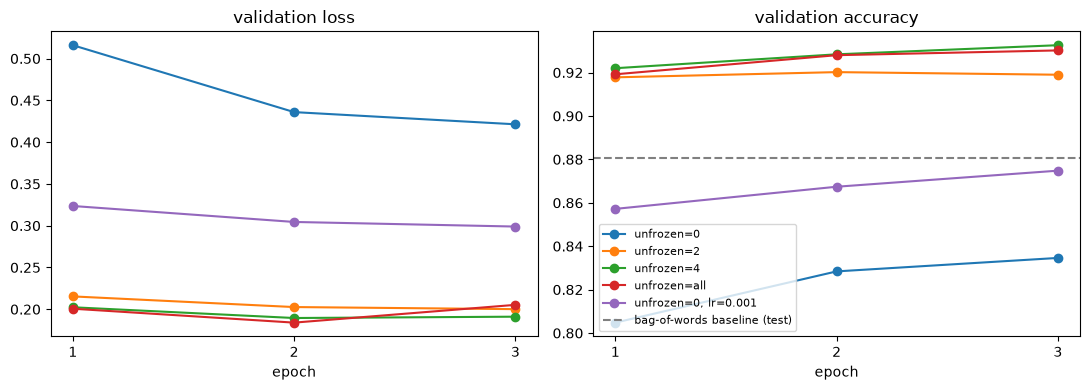

In [15]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for r in results:
    label = f"unfrozen={r['unfrozen']}" + ("" if r["lr"] == 2e-5 else f", lr={r['lr']:g}")
    epochs = [row["epoch"] for row in r["history"]]
    axes[0].plot(epochs, [row["val_loss"] for row in r["history"]], marker="o", label=label)
    axes[1].plot(epochs, [row["val_acc"] for row in r["history"]], marker="o", label=label)
axes[0].set(title="validation loss", xlabel="epoch", xticks=range(1, EPOCHS + 1))
axes[1].set(title="validation accuracy", xlabel="epoch", xticks=range(1, EPOCHS + 1))
axes[1].axhline(0.8805, color="gray", linestyle="--", label="bag-of-words baseline (test)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 8. Speed and memory of each freezing setting (controlled)

The training times above are wall-clock and pick up whatever else the machine was doing. Here every setting runs the
same 20 real training batches (bf16), timed with the GPU synchronised, as in section 5.

In [16]:
freeze_speed = {}
for unfrozen in (0, 2, 4, "all"):
    ms, peak = time_training_steps("bf16", timing_batches, unfrozen_layers=unfrozen)
    freeze_speed[str(unfrozen)] = ms
    print(f"unfrozen={unfrozen!s:>3}: {ms:6.1f} ms per training step | peak GPU memory {peak:.2f} GB | "
          f"{freeze_speed[str(unfrozen)] / freeze_speed['0'] if '0' in freeze_speed else 1:.1f}x the head-only time")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

unfrozen=  0:   32.9 ms per training step | peak GPU memory 0.95 GB | 1.0x the head-only time


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

unfrozen=  2:   61.8 ms per training step | peak GPU memory 1.57 GB | 1.9x the head-only time


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

unfrozen=  4:   91.9 ms per training step | peak GPU memory 2.25 GB | 2.8x the head-only time


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

unfrozen=all:  135.1 ms per training step | peak GPU memory 3.23 GB | 4.1x the head-only time


## 9. What the freezing experiment shows (DistilBERT)

| trained | test accuracy | test loss | step time vs head-only (section 8) |
|---|---|---|---|
| head only, LR 2e-5 | 82.96% | 0.419 | 1.0× |
| head only, LR 1e-3 | 87.12% | 0.302 | 1.0× |
| top 2 layers + head | 92.55% | 0.190 | about 1.8× |
| top 4 layers + head | 93.14% | 0.180 | about 2.7× |
| everything | **93.41%** | **0.178** | about 3.9× |

**1. Adapting the encoder is what matters, and most of the gain comes from the top 2 layers.** Going from head only to
the top 2 layers adds about 5.4 points (vs. the head at its better LR). Two more layers add 0.6, and the rest adds 0.3.
The cost grows steadily: unfreezing everything makes each step about 4× slower than head-only and needs about 3.4× the
GPU memory (section 8). If compute were tight, top 2 would give most of the accuracy for half the cost.

**2. Head-only was partly limited by the learning rate, but not only by that.** At LR 1e-3 the head reaches 87.1%
instead of 83.0%, so 2e-5 really was too small for a randomly initialised layer. Even at 1e-3, a frozen DistilBERT plus a
linear layer is **below the bag-of-words baseline (88.05%)**. A likely reason: DistilBERT was pretrained only on word-level
tasks (filling in masked words, imitating BERT), without BERT's next-sentence task, so its `[CLS]` vector was never
trained to summarise a whole text. It only becomes a useful summary once
the encoder is fine-tuned. Pretrained features are not automatically better features.

**3. Every run that updated the encoder beats all earlier models by 4.5–5.4 points**, and the earlier models needed
25 epochs to get there; these took 2–3.

**4. Overfitting starts at epoch 3 for top 4 and all, and checkpointing by validation loss caught it.** For those two
runs, epoch 3 had *higher* validation loss but *higher* validation accuracy than epoch 2. The model gets a few more
reviews right but becomes more confident on the ones it gets wrong. Epoch 2 was kept, and the test losses (0.18) are far
better calibrated than the BiGRU (1.04) and transformer (0.63) in the previous notebook, where the checkpoint was picked by accuracy.

**5. Caveat: one seed per setting.** With 25,000 test reviews the sampling error of an accuracy near 93% is about
±0.16 points (one standard error), and changing the seed usually moves fine-tuning results by a few tenths of a point. So
"top 4" vs. "all" (0.3 points apart) is not a real difference. "Head only" vs. "top 2" (5+ points) clearly is.

**Wall-clock times in section 7 are not comparable.** Some runs were slowed down several times by the machine while it
was unattended, which is why section 8 measures speed under controlled conditions.

## 10. Reproducibility check

The first attempt at section 7 was cut off by a system restart, but its head-only and top-2 runs had already finished
and saved their best checkpoints. They were trained by the same code with the same seed. Evaluating those old checkpoints
and comparing them with the rerun checks that the pipeline is reproducible. Results shouldn't be bit-identical, since some
GPU operations aren't deterministic, but they should agree to within about a tenth of a point.

In [17]:
OLD_CHECKPOINTS = Path("../interrupted_run_checkpoints")
for unfrozen in (0, 2):
    tag = f"distilbert_unfrozen-{unfrozen}_lr-2e-05"
    classifier = SentimentClassifier(MODEL_NAMES["distilbert"], unfrozen_layers=unfrozen)
    trainer = L.Trainer(precision="bf16-mixed", logger=False, enable_model_summary=False, enable_progress_bar=False)
    old_val = trainer.validate(classifier, make_loader("distilbert", "val", batch_size=64),
                               ckpt_path=OLD_CHECKPOINTS / f"{tag}.ckpt", verbose=False)[0]
    old_test = trainer.test(classifier, make_loader("distilbert", "test", batch_size=64),
                            ckpt_path=OLD_CHECKPOINTS / f"{tag}.ckpt", verbose=False)[0]
    rerun = json.loads((RESULTS_DIR / f"{tag}.json").read_text())
    print(f"unfrozen={unfrozen}: val acc  first attempt {old_val['val_acc']:.4f} | rerun {rerun['val_acc']:.4f}")
    print(f"           test acc first attempt {old_test['test_acc']:.4f} | rerun {rerun['test_acc']:.4f}")
    print(f"           test loss first attempt {old_test['test_loss']:.4f} | rerun {rerun['test_loss']:.4f}")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Using bfloat16 Automatic Mixed Precision (AMP)


GPU available: True (cuda), used: True


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


... (18 outputs left out)

Restoring states from the checkpoint path at ..\interrupted_run_checkpoints\distilbert_unfrozen-2_lr-2e-05.ckpt


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Loaded model weights from the checkpoint at ..\interrupted_run_checkpoints\distilbert_unfrozen-2_lr-2e-05.ckpt


unfrozen=2: val acc  first attempt 0.9194 | rerun 0.9190
           test acc first attempt 0.9254 | rerun 0.9255
           test loss first attempt 0.1898 | rerun 0.1898


**Result: reproducible.** The head-only checkpoint from the first attempt gives exactly the same validation and test
numbers as the rerun (to 4 decimals). For top 2, validation accuracy differs by 0.04 points and test accuracy by 0.01;
test loss is identical. That's the size of difference GPU non-determinism produces. So an interrupted and restarted
experiment gives the same results, and differences between settings in section 7 aren't artefacts of run-to-run instability.

## 11. The full-size models: BERT-base and RoBERTa-base

Both use the best setting from section 7: **everything trained**, with the same LR, warmup, weight decay, 3 epochs and checkpoint rule.

| | layers | parameters | pretraining |
|---|---|---|---|
| DistilBERT | 6 | 66M | distilled from BERT |
| BERT-base | 12 | 110M | masked words + next-sentence prediction, 16 GB of text |
| RoBERTa-base | 12 | 125M | masked words only, 160 GB of text, longer training, bigger batches |

DistilBERT vs. BERT shows the effect of **model size** (same tokenizer, same pretraining data). BERT vs. RoBERTa shows
the effect of **better pretraining** (same size, same architecture).

**Memory.** The 12-layer models need roughly twice the activation memory of DistilBERT. To stay well inside the GPU's
6 GB, they use **8 reviews per batch × 4 accumulation steps**, which still gives 32 reviews per optimizer step and the same
number of optimizer steps as DistilBERT.

In [18]:
for name in ("bert", "roberta"):
    results.append(run_experiment(name, "all", batch_size=8, accumulate=4))

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Using bfloat16 Automatic Mixed Precision (AMP)


GPU available: True (cuda), used: True


TPU available: False, using: 0 TPU cores


... (19 outputs left out)

Restoring states from the checkpoint path at C:\research\research-progress\notebooks\checkpoints\roberta_unfrozen-all_lr-2e-05.ckpt


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Loaded model weights from the checkpoint at C:\research\research-progress\notebooks\checkpoints\roberta_unfrozen-all_lr-2e-05.ckpt


roberta_unfrozen-all_lr-2e-05: kept epoch 2 | val acc 0.9522 loss 0.1331 | test acc 0.9568 loss 0.1219 | 20.5 min | 4.21 GB


## 12. Comparison with the earlier models

The first four rows are from `imdb_baselines_bigru_transformer.ipynb`: same data split, same test set, models trained
from random weights for 25 epochs. Their checkpoints were picked by validation accuracy (the flaw noted there), which
mainly inflates their test loss.

In [19]:
earlier = [("bag-of-words + logistic regression", 0.8805, 0.294), ("GRU + attention", 0.8718, 0.360),
           ("BiGRU + attention", 0.8662, 1.042), ("transformer encoder from scratch", 0.8571, 0.631)]
rows = [{"model": m, "trained": "from scratch", "test_acc": a, "test_loss": l} for m, a, l in earlier]
for r in results:
    if r["unfrozen"] in ("0", "all"):
        trained = "everything" if r["unfrozen"] == "all" else f"head only, LR {r['lr']:g}"
        rows.append({"model": r["model"], "trained": trained, "test_acc": r["test_acc"], "test_loss": r["test_loss"]})
comparison = pd.DataFrame(rows)
comparison["vs baseline (points)"] = (comparison["test_acc"] - 0.8805) * 100
print(comparison.round(4).to_string(index=False))

                             model             trained  test_acc  test_loss  vs baseline (points)
bag-of-words + logistic regression        from scratch    0.8805     0.2940                 0.000
                   GRU + attention        from scratch    0.8718     0.3600                -0.870
                 BiGRU + attention        from scratch    0.8662     1.0420                -1.430
  transformer encoder from scratch        from scratch    0.8571     0.6310                -2.340
                        distilbert head only, LR 2e-05    0.8296     0.4190                -5.086
                        distilbert          everything    0.9341     0.1776                 5.358
                        distilbert head only, LR 0.001    0.8712     0.3021                -0.930
                              bert          everything    0.9430     0.1576                 6.250
                           roberta          everything    0.9568     0.1219                 7.630


## 13. Conclusions

| model | test accuracy | test loss | errors on the 25,000 test reviews |
|---|---|---|---|
| bag-of-words + logistic regression (best earlier model) | 88.05% | 0.294 | 2,988 |
| DistilBERT, everything trained | 93.41% | 0.178 | 1,648 |
| BERT-base, everything trained | 94.30% | 0.158 | 1,425 |
| RoBERTa-base, everything trained | **95.68%** | **0.122** | **1,080** |

**1. Fine-tuning a pretrained model is a big step up.** RoBERTa-base beats the bag-of-words baseline by 7.6 points
and makes **64% fewer errors** (1,080 instead of 2,988). It does that after 2 epochs; the from-scratch models
trained for 25 and stayed below the baseline. Its test loss (0.122) is also the lowest of any model, so it's not just
more accurate but better calibrated.

**2. Both model size and pretraining matter, and pretraining matters more here.**
- DistilBERT → BERT-base (twice the layers, same tokenizer and pretraining data): **+0.9 points**.
- BERT-base → RoBERTa-base (same size and architecture, 10× more pretraining text, longer training, no next-sentence task): **+1.4 points**.

Both gaps are well above the ±0.16-point sampling error of the test set. They are single runs, though, so the exact
sizes would shift a little with other seeds.

**3. The result is in line with the literature.** Sun et al. (2019), "How to Fine-Tune BERT for Text Classification",
report about 94.6% for BERT-base on IMDB with the same head + tail truncation, trained on all 25,000 training reviews.
Our 94.3% uses 20,000 (5,000 are held out for validation).

**4. Two epochs are enough.** All three full fine-tuning runs (DistilBERT, BERT, RoBERTa) had their lowest validation
loss at epoch 2. At epoch 3, validation accuracy rose slightly but validation loss rose more: the models became
overconfident on the reviews they get wrong. Checkpointing by validation loss kept epoch 2 every time.

**5. Freezing trades accuracy for compute.** From section 9: training only the top 2 of DistilBERT's 6 layers gives 92.6%
(vs. 93.4% for everything) at under half the step time and memory. Training only the head isn't enough: it ends up below the baseline.

**Note on training times.** The wall-clock times in the tables are unreliable. BERT-base took 222 min while RoBERTa-base,
the same size, took 21 min. The machine slowed some unattended runs down several times over. Section 8 gives the controlled speed comparison.

**Possible next steps:**
- 2–3 seeds per model, to put error bars on the gaps above
- mean-pooling the frozen DistilBERT features instead of `[CLS]`, to test why head-only falls below the baseline
- the freezing experiment on RoBERTa